In [1]:
from pathlib import Path
from scipy.io import loadmat
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FS = 2000
data_path = Path("/Users/ala/Downloads/DB2_s1/S1_E1_A1.mat")

mat = loadmat(data_path)

emg = np.asarray(mat["emg"], dtype=np.float64)
labels = mat["restimulus"].ravel().astype(int)
repetitions = mat["rerepetition"].ravel().astype(int)

movement_names = {
    5: "Finger spreading",
    6: "Fist",
    9: "Supination",
    10: "Pronation"
}

assert len(emg) == len(labels) == len(repetitions)
assert np.isfinite(emg).all(), "EMG contains missing or infinite values."

print("EMG shape:", emg.shape)
print("Sampling rate:", FS, "Hz")
print("Selected movements:", movement_names)
print("Data loaded successfully!")

EMG shape: (1808331, 12)
Sampling rate: 2000 Hz
Selected movements: {5: 'Finger spreading', 6: 'Fist', 9: 'Supination', 10: 'Pronation'}
Data loaded successfully!


In [2]:
from scipy.signal import iirnotch, filtfilt, butter, sosfiltfilt

def preprocess(x, fs):
    # Remove interference around 60 Hz
    b_notch, a_notch = iirnotch(60, Q=30, fs=fs)
    x_notch = filtfilt(b_notch, a_notch, x, axis=0)

    # Keep frequencies between 20 and 450 Hz
    sos = butter(
        4,
        [20, 450],
        btype="bandpass",
        fs=fs,
        output="sos"
    )
    return sosfiltfilt(sos, x_notch, axis=0)

emg_filtered = preprocess(emg, FS)

assert emg_filtered.shape == emg.shape
assert np.isfinite(emg_filtered).all()

filter_summary = pd.DataFrame({
    "Channel": np.arange(1, emg.shape[1] + 1),
    "Before filtering (std)": emg.std(axis=0),
    "After filtering (std)": emg_filtered.std(axis=0)
})

display(filter_summary)
print("Filtered shape:", emg_filtered.shape)
print("Filtering completed!")

,Channel,Before filtering (std),After filtering (std)
0,1,0.000041,0.000040
1,2,0.000028,0.000027
2,3,0.000043,0.000042
3,4,0.000046,0.000045
4,5,0.000012,0.000011
5,6,0.000010,0.000010
6,7,0.000048,0.000046
7,8,0.000075,0.000073
8,9,0.000047,0.000046
9,10,0.000052,0.000051


Filtered shape: (1808331, 12)
Filtering completed!


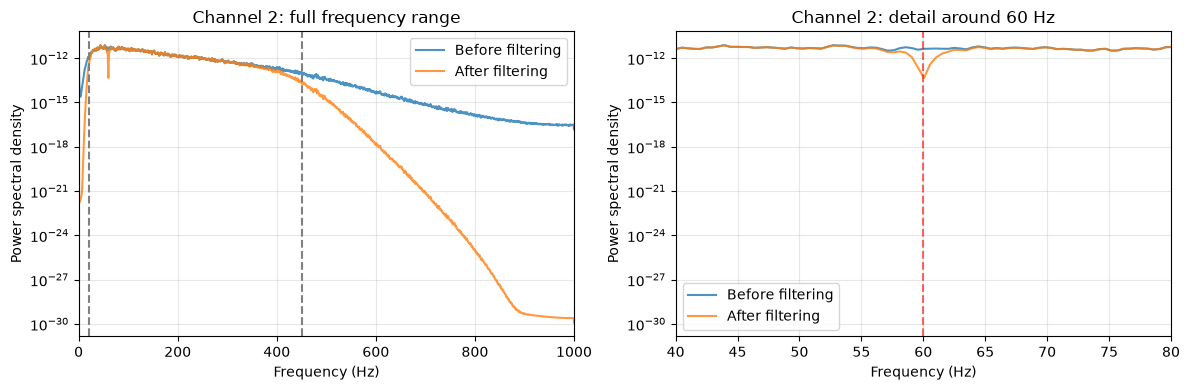

In [3]:
from scipy.signal import welch

# Compare Channel 2 over the same recording
channel = 1  # Python index 1 means Channel 2

freq, psd_before = welch(
    emg[:, channel],
    fs=FS,
    nperseg=4096
)

_, psd_after = welch(
    emg_filtered[:, channel],
    fs=FS,
    nperseg=4096
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax in axes:
    ax.semilogy(freq, psd_before, label="Before filtering", alpha=0.8)
    ax.semilogy(freq, psd_after, label="After filtering", alpha=0.8)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Power spectral density")
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[0].set_xlim(0, FS / 2)
axes[0].axvline(20, color="gray", linestyle="--")
axes[0].axvline(450, color="gray", linestyle="--")
axes[0].set_title("Channel 2: full frequency range")

axes[1].set_xlim(40, 80)
axes[1].axvline(60, color="red", linestyle="--", alpha=0.6)
axes[1].set_title("Channel 2: detail around 60 Hz")

plt.tight_layout()
plt.savefig("week5_filter_spectrum.png", dpi=200)
plt.show()

Segment shape: (4000, 12)
Segment duration: 2.0 seconds


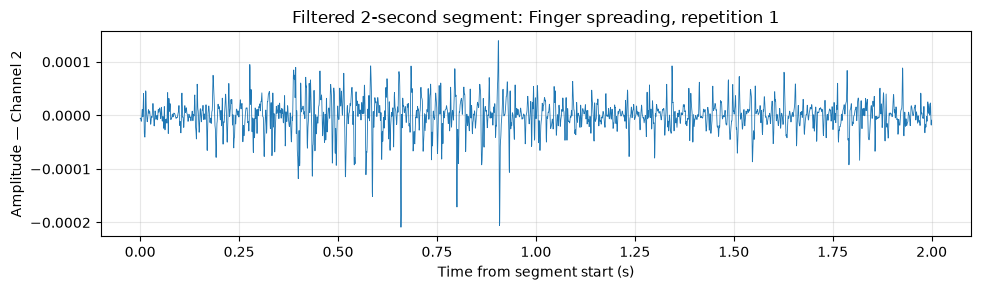

In [4]:
SEGMENT_SAMPLES = int(2.0 * FS)

# Find finger spreading, repetition 1
indices = np.flatnonzero(
    (labels == 5) & (repetitions == 1)
)

if len(indices) == 0:
    raise ValueError("Movement 5, repetition 1 was not found.")

# Separate any disconnected labeled intervals
runs = np.split(indices, np.flatnonzero(np.diff(indices) > 1) + 1)
run = max(runs, key=len)

if len(run) < SEGMENT_SAMPLES:
    raise ValueError("This movement interval is shorter than 2 seconds.")

# Take the middle 2 seconds, entirely inside the labeled interval
start = int(run[0]) + (len(run) - SEGMENT_SAMPLES) // 2
end = start + SEGMENT_SAMPLES

segment = emg_filtered[start:end]

assert segment.shape == (4000, 12)
assert np.all(labels[start:end] == 5)
assert np.all(repetitions[start:end] == 1)

print("Segment shape:", segment.shape)
print("Segment duration:", len(segment) / FS, "seconds")

# Display Channel 2
t = np.arange(len(segment)) / FS

plt.figure(figsize=(10, 3))
plt.plot(t, segment[:, 1], linewidth=0.6)
plt.title("Filtered 2-second segment: Finger spreading, repetition 1")
plt.xlabel("Time from segment start (s)")
plt.ylabel("Amplitude — Channel 2")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("week5_segment_example.png", dpi=200)
plt.show()

In [5]:
WIN = int(round(0.200 * FS))  # 400 samples
HOP = int(round(0.100 * FS))  # 200 samples

def make_windows(x, win=WIN, hop=HOP):
    if len(x) < win:
        raise ValueError("Signal is shorter than one window.")

    return np.stack([
        x[start:start + win]
        for start in range(0, len(x) - win + 1, hop)
    ])

windows = make_windows(segment)

assert windows.shape == (19, 400, 12)

print("Window length:", WIN, "samples")
print("Step size:", HOP, "samples")
print("Overlap:", 100 * (1 - HOP / WIN), "%")
print("Window array shape:", windows.shape)

Window length: 400 samples
Step size: 200 samples
Overlap: 50.0 %
Window array shape: (19, 400, 12)


In [6]:
def td_features(w, th=0.01):
    """Return features in this order: RMS, MAV, WL, ZC, SSC."""
    rms = np.sqrt(np.mean(w ** 2, axis=0))
    mav = np.mean(np.abs(w), axis=0)

    d = np.diff(w, axis=0)
    wl = np.sum(np.abs(d), axis=0)

    zc = np.sum(
        (w[:-1] * w[1:] < 0) & (np.abs(d) >= th),
        axis=0
    )

    # Same SSC definition as the lecture example
    ssc = np.sum(d[:-1] * d[1:] < 0, axis=0)

    return np.concatenate([rms, mav, wl, zc, ssc])


# Check the first example window
features = td_features(windows[0])

assert features.shape == (60,)
assert np.isfinite(features).all()

feature_table = pd.DataFrame(
    features.reshape(5, 12).T,
    columns=["RMS", "MAV", "WL", "ZC", "SSC"]
)
feature_table.insert(0, "Channel", np.arange(1, 13))

display(feature_table)
print("Feature vector shape:", features.shape)

# Compare the lecture threshold with no amplitude threshold
features_no_threshold = td_features(windows[0], th=0.0)

print("ZC with threshold 0.01:", features[36:48].astype(int))
print("ZC with threshold 0:", features_no_threshold[36:48].astype(int))

,Channel,RMS,MAV,WL,ZC,SSC
0,1,0.000025,0.000019,0.003378,0.0,95.0
1,2,0.000019,0.000013,0.002529,0.0,92.0
2,3,0.000081,0.000056,0.009048,0.0,79.0
3,4,0.000051,0.000039,0.007246,0.0,90.0
4,5,0.000024,0.000019,0.003151,0.0,80.0
5,6,0.000009,0.000007,0.000970,0.0,89.0
6,7,0.000037,0.000029,0.003847,0.0,66.0
7,8,0.000121,0.000094,0.017024,0.0,95.0
8,9,0.000093,0.000073,0.012909,0.0,87.0
9,10,0.000054,0.000041,0.005954,0.0,84.0


Feature vector shape: (60,)
ZC with threshold 0.01: [0 0 0 0 0 0 0 0 0 0 0 0]
ZC with threshold 0: [56 55 51 51 47 36 39 58 53 47 37 46]


In [7]:
ZC_THRESHOLD = 0.0

trial_rows = []

for movement_id in movement_names:
    rep_ids = np.unique(repetitions[labels == movement_id])
    rep_ids = rep_ids[rep_ids > 0]

    for rep in rep_ids:
        indices = np.flatnonzero(
            (labels == movement_id) & (repetitions == rep)
        )

        # Keep the longest continuous labeled interval
        runs = np.split(
            indices,
            np.flatnonzero(np.diff(indices) > 1) + 1
        )
        run = max(runs, key=len)

        trial_rows.append({
            "trial_id": f"S1_M{movement_id}_R{rep}",
            "movement_id": int(movement_id),
            "repetition": int(rep),
            "start": int(run[0]),
            "end": int(run[-1]) + 1,
            "duration_s": len(run) / FS,
            "usable": len(run) >= SEGMENT_SAMPLES
        })

trials = pd.DataFrame(trial_rows)

display(trials[
    ["trial_id", "movement_id", "repetition", "duration_s", "usable"]
])

print("Total trials:", len(trials))
print("Trials at least 2 seconds:", int(trials["usable"].sum()))
print("Trials shorter than 2 seconds:", int((~trials["usable"]).sum()))

,trial_id,movement_id,repetition,duration_s,usable
0,S1_M5_R1,5,1,3.5130,True
1,S1_M5_R2,5,2,3.5145,True
2,S1_M5_R3,5,3,3.7025,True
3,S1_M5_R4,5,4,3.3635,True
4,S1_M5_R5,5,5,3.1755,True
5,S1_M5_R6,5,6,2.7935,True
6,S1_M6_R1,6,1,2.2425,True
7,S1_M6_R2,6,2,2.2530,True
8,S1_M6_R3,6,3,2.1725,True
9,S1_M6_R4,6,4,2.1730,True


Total trials: 24
Trials at least 2 seconds: 22
Trials shorter than 2 seconds: 2


In [8]:
from sklearn.model_selection import train_test_split

# Keep trials containing at least 2 seconds of continuous movement
usable_trials = trials.loc[trials["usable"]].copy()

# IMPORTANT: split whole trials, not individual windows
train_trials, test_trials = train_test_split(
    usable_trials,
    test_size=0.2,
    stratify=usable_trials["movement_id"],
    random_state=42
)

train_trials = train_trials.reset_index(drop=True)
test_trials = test_trials.reset_index(drop=True)

# Confirm that no trial appears in both sets
train_ids = set(train_trials["trial_id"])
test_ids = set(test_trials["trial_id"])

assert train_ids.isdisjoint(test_ids)
assert set(train_trials["movement_id"]) == set(movement_names)
assert set(test_trials["movement_id"]) == set(movement_names)

split_summary = pd.DataFrame({
    "Train trials": train_trials.groupby("movement_id").size(),
    "Test trials": test_trials.groupby("movement_id").size()
}).fillna(0).astype(int)

split_summary.index.name = "Movement ID"
display(split_summary)

print("Training trials:", len(train_trials))
print("Test trials:", len(test_trials))
print("Shared trials:", len(train_ids & test_ids))

# Save the split so it can be reproduced and checked
train_trials.to_csv("week5_train_trials.csv", index=False)
test_trials.to_csv("week5_test_trials.csv", index=False)
trials.loc[~trials["usable"]].to_csv(
    "week5_excluded_trials.csv", index=False
)

,Train trials,Test trials
Movement ID,,
5,5,1
6,3,1
9,5,1
10,4,2


Training trials: 17
Test trials: 5
Shared trials: 0


In [9]:
# Map movement IDs to class labels 0–3
class_ids = list(movement_names)
label_map = {
    movement_id: class_index
    for class_index, movement_id in enumerate(class_ids)
}

feature_names = [
    f"{feature}_Ch{channel}"
    for feature in ["RMS", "MAV", "WL", "ZC", "SSC"]
    for channel in range(1, 13)
]

def build_dataset(trial_table):
    X, y, groups = [], [], []

    for trial in trial_table.itertuples(index=False):
        # Filter only this trial's continuous interval
        raw_trial = emg[trial.start:trial.end]
        filtered_trial = preprocess(raw_trial, FS)

        # Take the middle two seconds
        offset = (len(filtered_trial) - SEGMENT_SAMPLES) // 2
        seg = filtered_trial[offset:offset + SEGMENT_SAMPLES]

        assert seg.shape == (4000, 12)

        trial_windows = make_windows(seg)
        assert trial_windows.shape == (19, 400, 12)

        for window in trial_windows:
            X.append(td_features(window, th=ZC_THRESHOLD))
            y.append(label_map[trial.movement_id])
            groups.append(trial.trial_id)

    return (
        np.stack(X),
        np.asarray(y, dtype=int),
        np.asarray(groups)
    )


X_train, y_train, groups_train = build_dataset(train_trials)
X_test, y_test, groups_test = build_dataset(test_trials)

assert X_train.shape == (len(train_trials) * 19, 60)
assert X_test.shape == (len(test_trials) * 19, 60)
assert np.isfinite(X_train).all()
assert np.isfinite(X_test).all()
assert set(groups_train).isdisjoint(set(groups_test))

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Test labels:", y_test.shape)
print("Class mapping:", label_map)

distribution = pd.DataFrame({
    "Movement": [movement_names[mid] for mid in class_ids],
    "Class label": range(len(class_ids)),
    "Train windows": [
        int((y_train == i).sum()) for i in range(len(class_ids))
    ],
    "Test windows": [
        int((y_test == i).sum()) for i in range(len(class_ids))
    ]
})

display(distribution)

Training features: (323, 60)
Test features: (95, 60)
Training labels: (323,)
Test labels: (95,)
Class mapping: {5: 0, 6: 1, 9: 2, 10: 3}


,Movement,Class label,Train windows,Test windows
0,Finger spreading,0,95,19
1,Fist,1,57,19
2,Supination,2,95,19
3,Pronation,3,76,38


In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

assert np.isfinite(X_train_scaled).all()
assert np.isfinite(X_test_scaled).all()

# Constant features remain zero after scaling
nonconstant = np.ptp(X_train, axis=0) > 0

assert np.allclose(
    X_train_scaled.mean(axis=0), 0, atol=1e-8
)
assert np.allclose(
    X_train_scaled.std(axis=0)[nonconstant], 1, atol=1e-8
)

print(
    "Largest absolute training mean:",
    np.abs(X_train_scaled.mean(axis=0)).max()
)
print(
    "Training std range (nonconstant features):",
    X_train_scaled.std(axis=0)[nonconstant].min(),
    X_train_scaled.std(axis=0)[nonconstant].max()
)
print("Constant features:", int((~nonconstant).sum()))

# Save scaled features, original features, and reproducibility details
output_path = Path("dataset.npz")

np.savez_compressed(
    output_path,
    Xtr=X_train_scaled,
    ytr=y_train,
    Xte=X_test_scaled,
    yte=y_test,
    Xtr_raw=X_train,
    Xte_raw=X_test,
    groups_train=groups_train,
    groups_test=groups_test,
    feature_names=np.asarray(feature_names),
    movement_ids=np.asarray(class_ids),
    class_names=np.asarray([
        movement_names[mid] for mid in class_ids
    ]),
    scaler_mean=scaler.mean_,
    scaler_scale=scaler.scale_,
    fs=FS,
    segment_samples=SEGMENT_SAMPLES,
    window_samples=WIN,
    hop_samples=HOP,
    zc_threshold=ZC_THRESHOLD
)

# Verify the saved file
with np.load(output_path, allow_pickle=False) as saved:
    assert np.array_equal(saved["Xtr"], X_train_scaled)
    assert np.array_equal(saved["Xte"], X_test_scaled)
    print("Saved training shape:", saved["Xtr"].shape)
    print("Saved test shape:", saved["Xte"].shape)

print("Saved successfully:", output_path.resolve())

Largest absolute training mean: 2.6191639156791617e-15
Training std range (nonconstant features): 0.9999999999999992 1.0000000000000024
Constant features: 0
Saved training shape: (323, 60)
Saved test shape: (95, 60)
Saved successfully: /Users/ala/semg-auth/dataset.npz


## 전처리 및 특징 추출 결과

Ninapro DB2 피험자 1의 12채널 sEMG 데이터를 사용하였다.
샘플링 주파수는 2,000 Hz이며, 네 가지 동작을 분석하였다.

60 Hz 노치 필터(Q=30)와 20–450 Hz 4차 Butterworth
대역통과 필터를 양방향으로 적용하였다.
스펙트럼에서 60 Hz 주변과 통과 대역 밖의 성분이 감소함을 확인하였다.
검증 그림은 전체 기록을 사용했지만, 최종 데이터셋에서는
각 시행을 독립적으로 필터링하였다.

## 분석 구간 및 제외한 시행

각 동작·반복의 가장 긴 연속 라벨 구간에서 가운데 2초를 사용하였다.
이는 공개 데이터에 맞게 정한 실습 설정이다.

주먹 쥐기의 반복 5와 6은 각각 1.9645초와 1.9730초로,
2초보다 짧아 제외하였다.
전체 24개 시행 중 22개 시행을 사용하였다.

## 윈도우 설정 근거

### 200 ms를 선택한 이유
200 ms 구간은 짧은 시간 동안의 근전도 신호를 요약하면서
동작 중 나타나는 변화를 살펴볼 수 있게 한다.
또한 강의와 같은 시간 길이를 사용하여 특징 추출 과정을 비교하기 쉽다.

### 오버랩 50%를 선택한 이유
100 ms 간격으로 이동하면 인접한 윈도우 사이의 신호 변화를
연속적으로 살펴볼 수 있다.
다만 겹친 윈도우는 독립적인 시행이 아니므로 같은 시행의
윈도우가 학습셋과 테스트셋에 나뉘지 않도록 하였다.

2초는 4,000샘플, 200 ms는 400샘플, 100 ms는 200샘플이다.
따라서 시행마다 19개 윈도우가 생성되었다.

## 특징 구성 및 임계값

각 채널에서 RMS, MAV, WL, ZC, SSC를 계산하였다.
12채널에 특징 5종을 적용하여 윈도우마다 60차원 벡터를 만들었다.
강의의 5채널·25차원과 다른 점은 공개 데이터의 채널 수 때문이다.

특징 순서는 RMS의 채널 1–12, MAV의 채널 1–12,
WL의 채널 1–12, ZC의 채널 1–12, SSC의 채널 1–12이다.

강의의 ZC 임계값 0.01을 적용했을 때 예시 윈도우의
모든 채널에서 ZC가 0으로 나타났다.
본 실습에서는 신호 크기를 고려하여 임계값을 0으로 변경하였다.
따라서 작은 부호 변화도 계산되며 잡음에 민감할 수 있다.
SSC는 강의 코드와 같이 별도 임계값 없이 기울기의 부호 변화를 계산하였다.

## 데이터 분할 및 표준화

윈도우 생성 전에 시행 단위로 학습셋과 테스트셋을 분할하였다.
클래스 비율을 고려한 층화 분할과 random_state=42를 사용하였다.
학습 시행은 17개, 테스트 시행은 5개이며 중복 시행은 없다.

| 동작 | 클래스 | 학습 윈도우 | 테스트 윈도우 |
|---|---|---|---|
| 손가락 벌리기 | 0 | 95 | 19 |
| 주먹 쥐기 | 1 | 57 | 19 |
| 회외 | 2 | 95 | 19 |
| 회내 | 3 | 76 | 38 |
| 합계 | — | 323 | 95 |

StandardScaler는 학습셋에만 fit하고 테스트셋에는 transform만 적용하였다.
학습 특징의 평균은 약 0, 표준편차는 약 1이며 상수 특징은 없었다.
최종 배열 크기는 학습셋 (323, 60), 테스트셋 (95, 60)이다.

## 최종 결과

표준화된 특징, 클래스 라벨, 원래 특징과 시행 ID 등을
dataset.npz에 저장하였다.
이번 실습에서는 전처리와 특징 데이터셋 구성을 완료했으며,
모델 학습 및 성능 평가는 수행하지 않았다.

한 피험자의 네 동작만 사용했고 일부 시행을 제외했으므로,
이 데이터셋으로 얻을 후속 결과를 다른 사람에게 일반화하기는 어렵다.